In [1]:
#0.모듈 사용
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import pandas as pd
from tqdm.auto import tqdm

# GPU 사용 설정
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 사용할 수 없습니다. PyTorch CUDA 환경과 커널을 확인하세요.")

device = torch.device("cuda:0")
torch.backends.cudnn.benchmark = True
print(f"현재 사용하는 디바이스: {device}")
print(f"GPU 장치명: {torch.cuda.get_device_name(0)}")

현재 사용하는 디바이스: cuda:0
GPU 장치명: NVIDIA GeForce RTX 3060


In [2]:
#데이터셋 교정하기 전 버전 코드

#1. 데이터셋 준비
dataset_path = "CNN_train_test/CNN_train_test_image"
batch_size = 32

# ConvNeXt 모델에 맞는 이미지 전처리 (Resize 및 ImageNet 정규화)
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

# 전체 데이터셋 로드
full_dataset = datasets.ImageFolder(root=dataset_path, transform=data_transforms)
class_names = full_dataset.classes
num_classes = len(class_names)
print("인식된 패션 무드 목록:", class_names)
print(f"총 이미지 파일 수: {len(full_dataset)}")

# Train / Validation 데이터셋 분할 (8:2 비율)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(
    full_dataset, [train_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

# DataLoader 생성
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

인식된 패션 무드 목록: ['기타', '레트로', '로맨틱', '리조트', '매니시', '모던', '밀리터리', '섹시', '소피스트케이티드', '스트리트', '스포티', '아방가르드', '오리엔탈', '웨스턴', '젠더리스', '컨트리', '클래식', '키치', '톰보이', '펑크', '페미닌', '프레피', '히피', '힙합']
총 이미지 파일 수: 120975


In [3]:
# ConvNeXt-Tiny 모델 로드
weights = models.ConvNeXt_Tiny_Weights.DEFAULT
mood_model = models.convnext_tiny(weights=weights)

# 사전학습된 가중치 동결 (특징 추출기 고정)
for param in mood_model.parameters():
    param.requires_grad = False

# 최종 분류기(Classifier) 구조 변경 (마지막 분류 레이어를 무드 개수에 맞게 교체)
# ConvNeXt의 기본 classifier 구조는 [LayerNorm, Flatten, Linear] 형태입니다.
in_features = mood_model.classifier[2].in_features
mood_model.classifier = nn.Sequential(
    nn.Flatten(1),
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
)

# 모델을 설정한 디바이스(GPU 또는 CPU)로 이동
mood_model = mood_model.to(device)

# 손실 함수 및 옵티마이저 정의
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mood_model.classifier.parameters(), lr=0.001)
amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

print(mood_model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

In [6]:
epochs = 10
train_acc_history = []
val_acc_history = []

for epoch in range(epochs):
    # --- [1] 학습 단계 ---
    mood_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]", unit="batch")
    for batch_index, (inputs, labels) in enumerate(train_bar):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if epoch == 0 and batch_index == 0:
            print(f"model_device={next(mood_model.parameters()).device}, input_device={inputs.device}, batch_shape={tuple(inputs.shape)}")

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
            outputs = mood_model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{correct_train / total_train * 100:.1f}%")

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train
    train_acc_history.append(epoch_train_acc)

    # --- [2] 검증 단계 ---
    mood_model.eval()
    correct_val = 0
    total_val = 0
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch + 1}/{epochs} [Valid]", unit="batch")

    with torch.inference_mode():
        for inputs, labels in val_bar:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
                outputs = mood_model(inputs)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()
            val_bar.set_postfix(acc=f"{correct_val / total_val * 100:.1f}%")

    epoch_val_acc = correct_val / total_val
    val_acc_history.append(epoch_val_acc)
    print(f"Epoch [{epoch + 1}/{epochs}] | Train Loss: {epoch_train_loss:.4f} | "
          f"Train Acc: {epoch_train_acc * 100:.2f}% | Val Acc: {epoch_val_acc * 100:.2f}%")
 
print("학습 완료!")


Epoch 1/10 [Train]:   0%|          | 0/3025 [00:17<?, ?batch/s]

model_device=cuda:0, input_device=cuda:0, batch_shape=(32, 3, 224, 224)


KeyboardInterrupt: 

In [ ]:
from PIL import Image

def predict_image(img_path):
    # 1. 이미지 RGB 변환
    img = Image.open(img_path).convert('RGB')
    
    # 2. 전처리, 4차원 텐서로 변환
    img_tensor = data_transforms(img).unsqueeze(0).to(device)
    
    # 3. 모델에게 예측 요청
    mood_model.eval()
    with torch.inference_mode():
        outputs = mood_model(img_tensor)
        prob = torch.softmax(outputs, dim=1)

        confidence, idx = torch.max(prob, dim=1) #가장 높은 것 점수, 인덱스
        
        pred_mood_name = class_names[idx.item()] # 분류명
        confidence_score = confidence.item()     # 신뢰점수 (확률값)

    print(f'예측: {pred_mood_name} ({confidence_score:.2f})')

In [ ]:
# 모델 저장
os.makedirs("Model", exist_ok=True)
model_path = "Model/fashion_mood_model_pytorch.pth"
torch.save(mood_model.state_dict(), model_path)

print(f"모델 성공적 저장: {model_path}")

모델 성공적 저장: Model/fashion_mood_model_pytorch.pth


아래는 테스트 및 수치 확인 등

In [ ]:
from pathlib import Path
from IPython.display import Image as ShowImage, display

# 내려받은 의상 사진 10장을 차례로 예측
for path in sorted(Path("test_assets/internet_outfits/images").glob("*.jpg")):
    print(f"\n테스트 이미지: {path.name}")
    display(ShowImage(filename=str(path), width=200))
    predict_image(str(path))

In [ ]:
import numpy as np
import pandas as pd
from torchvision import datasets
from IPython.display import display, HTML

# 이미지 파일을 읽어 학습하지 않고, 폴더별 개수만 집계
dataset_info = datasets.ImageFolder(
    "CNN_train_test/CNN_train_test_image"
)

counts = np.bincount(
    dataset_info.targets,
    minlength=len(dataset_info.classes)
)

stats = pd.DataFrame({
    "무드": dataset_info.classes,
    "이미지 수": counts,
    "비율": counts / counts.sum() * 100,
})

# 표시 형식 지정
formatted = stats.copy()
formatted["이미지 수"] = formatted["이미지 수"].map("{:,}".format)
formatted["비율"] = formatted["비율"].map("{:.2f}%".format)

# 좌우 두 묶음으로 배치
middle = (len(formatted) + 1) // 2
table = pd.concat([
    formatted.iloc[:middle].reset_index(drop=True),
    formatted.iloc[middle:].reset_index(drop=True),
], axis=1).fillna("")

display(HTML(table.to_html(index=False)))

print(f"총 이미지: {counts.sum():,}장")
print(f"클래스: {len(counts)}개")
print(f"클래스별 이미지 수 중앙값: {np.median(counts):,.0f}장")

무드,이미지 수,비율,무드,이미지 수,비율
기타,546,0.45%,오리엔탈,512,0.42%
레트로,845,0.70%,웨스턴,220,0.18%
로맨틱,"9,130",7.55%,젠더리스,"1,547",1.28%
리조트,"10,434",8.62%,컨트리,"4,065",3.36%
매니시,"1,091",0.90%,클래식,"4,931",4.08%
모던,"9,997",8.26%,키치,602,0.50%
밀리터리,449,0.37%,톰보이,941,0.78%
섹시,794,0.66%,펑크,51,0.04%
소피스트케이티드,"4,049",3.35%,페미닌,"11,060",9.14%
스트리트,"56,138",46.40%,프레피,321,0.27%


총 이미지: 120,975장
클래스: 24개
클래스별 이미지 수 중앙값: 893장


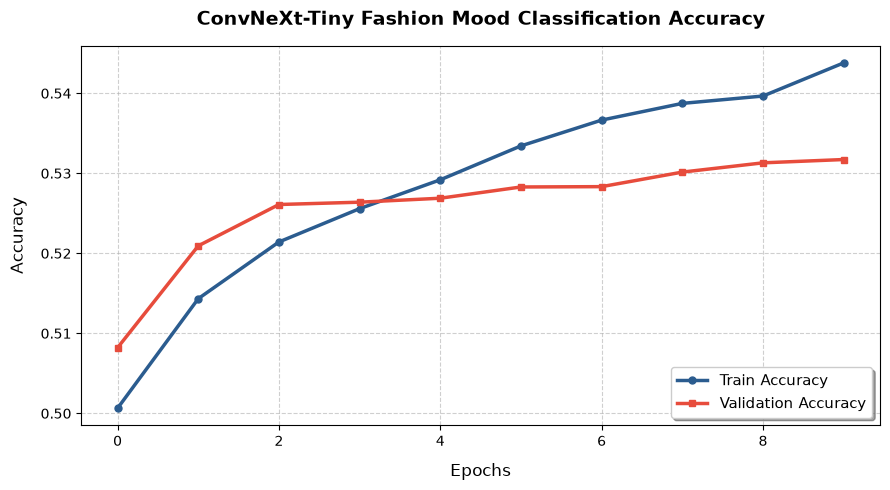

In [ ]:
import matplotlib.pyplot as plt

# 1. 그래프 크기 및 스타일 설정 (보고서 제출용 고해상도 느낌)
plt.figure(figsize=(9, 5), dpi=100)

# 2. 선 스타일 개선 (마커 추가 및 부드러운 곡선/직선 연출)
plt.plot(
    train_acc_history, 
    label='Train Accuracy', 
    color='#2b5c8f',       # 세련된 진한 파란색
    linewidth=2.5, 
    marker='o',            # 각 에포크마다 동그란 마커 표시
    markersize=5
)

plt.plot(
    val_acc_history, 
    label='Validation Accuracy', 
    color='#e74c3c',       # 눈에 잘 띄는 코랄레드 색상
    linewidth=2.5, 
    marker='s',            # 검증은 네모난 마커 표시
    markersize=5
)

# 3. 타이틀 및 라벨 디자인 (폰트 크기 및 여백 조정)
plt.title('ConvNeXt-Tiny Fashion Mood Classification Accuracy', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12, labelpad=10)
plt.ylabel('Accuracy', fontsize=12, labelpad=10)

# 4. Y축 범위를 0.0 ~ 1.0 (또는 0% ~ 100%)로 보기 좋게 고정하거나 여유 두기
# 만약 Accuracy가 0~1 사이 값이라면 아래 주석을 해제하세요.
# plt.ylim(0.0, 1.05)

# 5. 그리드 및 범례(Legend) 스타일링
plt.grid(True, linestyle='--', alpha=0.6)  # 점선 그리드 적용
plt.legend(fontsize=11, loc='lower right', frameon=True, shadow=True)

# 6. 레이아웃 최적화 및 출력
plt.tight_layout()
plt.show()

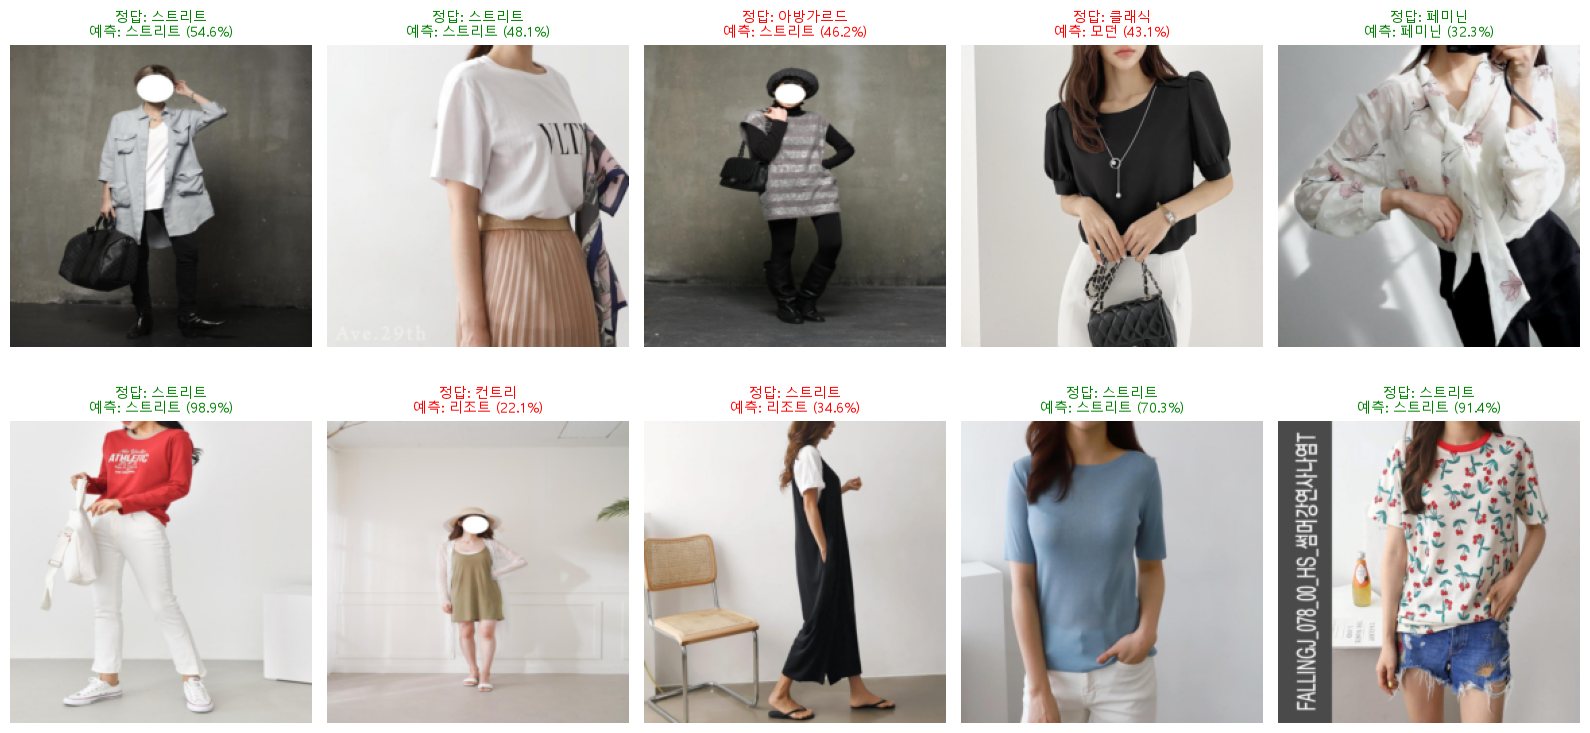

In [ ]:
# 한글 표시
plt.rcParams["font.family"] = "Malgun Gothic"

# 검증 데이터에서 최대 10장 가져오기
images, labels = next(iter(val_loader))
images, labels = images[:10], labels[:10]

# 모델 예측: 출력 점수를 softmax 확률로 변환
mood_model.eval() 
with torch.inference_mode():
    outputs = mood_model(images.to(device))
    confidences, predictions = torch.softmax(outputs, dim=1).max(dim=1)

predictions = predictions.cpu()
confidences = confidences.cpu()

# 학습 전처리의 정규화를 되돌려 원래 색상으로 표시
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
images = (images.cpu() * std + mean).clamp(0, 1)

# 2행 5열 시각화
fig, axes = plt.subplots(2, 5, figsize=(16, 8))

for idx, ax in enumerate(axes.flat):
    ax.axis("off")
    if idx >= len(images):
        continue

    # RGB 이미지는 (채널, 높이, 너비) → (높이, 너비, 채널)
    ax.imshow(images[idx].permute(1, 2, 0).numpy())

    actual = class_names[labels[idx].item()]
    predicted = class_names[predictions[idx].item()]
    color = "green" if actual == predicted else "red"

    ax.set_title(
        f"정답: {actual}\n예측: {predicted} ({confidences[idx].item():.1%})",
        color=color,
        fontsize=10,
    )

plt.tight_layout()
plt.show()